# 03 - Analyse non supervisée & labellisation faible
**Branche** : `feature/03-clustering`

PCA → K-Means / GMM / Agglomératif / DBSCAN (k = 2 comme le jeu labellisé) ; ARI calculé sur les 100 images labellisées. **Ne pas attendre un ARI parfait.**

In [2]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from brainscanai.config import load_config, resolve_path
from brainscanai.utils import set_seed

cfg = load_config()
set_seed(cfg["seed"])
PROC, FEAT = resolve_path(cfg, "processed", create=True), resolve_path(cfg, "features", create=True)
FIG, TAB = resolve_path(cfg, "figures", create=True), resolve_path(cfg, "tables", create=True)
from brainscanai.features.io import load_features
from brainscanai.clustering.reduce import *
from brainscanai.clustering.cluster import run_all
from brainscanai.clustering.evaluate import evaluate_all, purity
from brainscanai.evaluation.plots import plot_embedding_2d, save_fig
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import normalize

In [3]:
cc = cfg['clustering']
manifest = pd.read_csv(PROC / 'manifest_clean.csv')
X, m = load_features(FEAT / 'embeddings.npz', manifest)
Xs, _ = standardize(X)
Z, pca = pca_reduce(Xs, 0.95, cfg['seed'])   # PCA exploratoire (95 % de variance) : sert à l'analyse de sensibilité
Z.shape

(1305, 663)

## Choix de la dimension de la PCA (analyse de sensibilité)
La PCA à 95 % de variance conserve beaucoup de dimensions (663 pour ~1 300 images) : trop pour un clustering (concentration des distances, bruit). On compare plusieurs dimensions, avec et sans normalisation L2, sur la silhouette (sans labels) et l'ARI (sur les labellisées).

In [4]:
mask = m.label.to_numpy() >= 0
pca_full = PCA(random_state=cfg['seed']).fit(Xs)      # une seule PCA, on tronque ensuite
Zfull = pca_full.transform(Xs)
rows = []
for d in [5, 10, 20, 30, 50, 100, 200, Z.shape[1]]:
    Zd = Zfull[:, :d]
    for l2 in [False, True]:                           # normaliser L2 = géométrie « cosinus »
        Zk = normalize(Zd) if l2 else Zd
        lab = KMeans(2, n_init=20, random_state=cfg['seed']).fit_predict(Zk)
        rows.append(dict(dims=d, l2_norm=l2, var=pca_full.explained_variance_ratio_[:d].sum(),
                         silhouette=silhouette_score(Zk, lab),
                         ARI=adjusted_rand_score(m.label[mask], lab[mask])))
pca_sensitivity = pd.DataFrame(rows).round(3)
pca_sensitivity.to_csv(TAB / 'pca_sensitivity.csv', index=False)
pca_sensitivity

,dims,l2_norm,var,silhouette,ARI
0,5,False,0.188,0.276,0.219
1,5,True,0.188,0.296,0.539
2,10,False,0.257,0.217,0.219
3,10,True,0.257,0.216,0.510
4,20,False,0.337,0.178,0.219
5,20,True,0.337,0.171,0.570
6,30,False,0.390,0.165,0.219
7,30,True,0.390,0.153,0.570
8,50,False,0.464,0.151,0.219
9,50,True,0.464,0.133,0.570


## Espace de clustering retenu
La dimension (`pca_components`) et la normalisation L2 (`l2_normalize`) sont lues dans `configs/config.yaml` : **le même espace est utilisé par les scripts et le notebook 04** pour fabriquer les labels faibles. Les ARI sur 100 images ont une forte incertitude (écart-type de l'ordre de 0,1) : ne pas sur-interpréter des différences de quelques centièmes.

In [5]:
Zc, _ = prepare_clustering_space(X, cc['pca_components'], cc['l2_normalize'], cfg['seed'])
print('espace de clustering :', Zc.shape, '| normes ~ 1 :', bool(np.allclose(np.linalg.norm(Zc, axis=1), 1)) if cc['l2_normalize'] else 'L2 désactivée')

espace de clustering : (1305, 50) | normes ~ 1 : True


## Visualisation 2D (t-SNE sur l'espace retenu) - vérité terrain

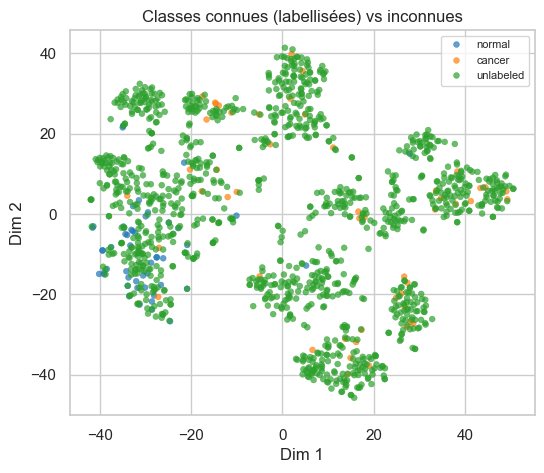

In [6]:
coords = tsne_embed(Zc, cc['tsne_perplexity'], cfg['seed'])
plot_embedding_2d(coords, m.label_name, 'Classes connues (labellisées) vs inconnues'); plt.show()

## Comparaison de 4 algorithmes (dans l'espace retenu)
À comparer aussi avec le même tableau sans L2 (`l2_normalize: false`) pour documenter l'effet de la normalisation. Renseigner ensuite `selected_method` dans la config.

In [7]:
results = run_all(Zc, cc['n_clusters'], cfg['seed'], cc['dbscan_min_samples'])
table = evaluate_all(results, Zc, m.label.to_numpy())
table.to_csv(TAB / 'clustering_comparison.csv')
table

,n_clusters,noise_pct,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,homogeneity,completeness,v_measure,purity
method,,,,,,,,,,,
kmeans,2,0.0000,0.1327,2.3544,212.8071,0.5696,0.5012,0.4970,0.5054,0.5012,0.8788
gmm,2,0.0000,0.0661,2.0414,123.6810,0.1831,0.2955,0.2579,0.3459,0.2955,0.7172
agglomerative,2,0.0000,0.1198,2.4682,187.3384,0.4806,0.4042,0.4017,0.4068,0.4042,0.8485
dbscan,1,3.7548,NaN,NaN,NaN,-0.0004,0.0045,0.0027,0.0138,0.0045,0.5152


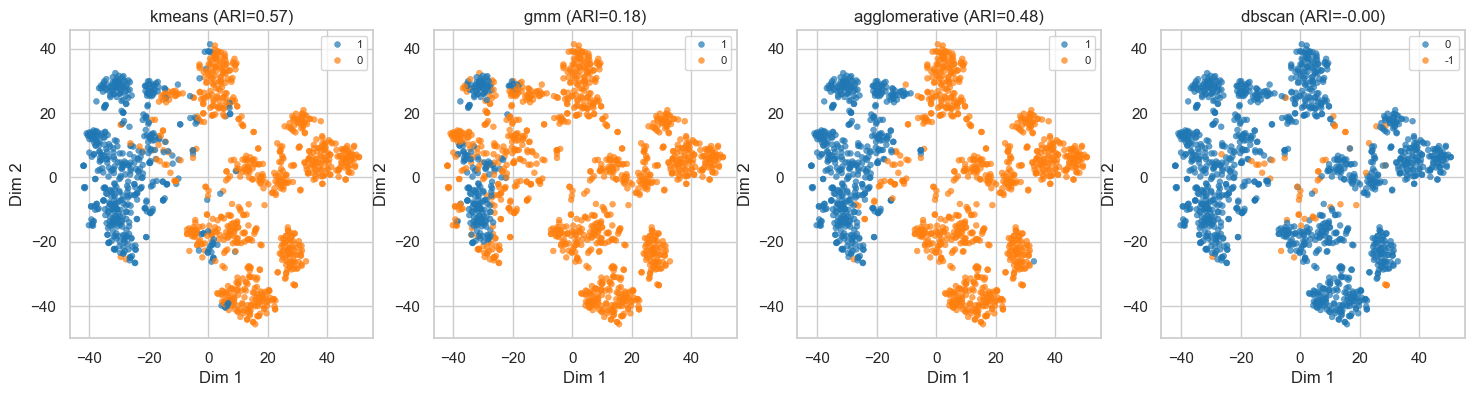

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, r) in zip(axes, results.items()):
    plot_embedding_2d(coords, r.labels, f"{name} (ARI={table.loc[name, 'ARI']:.2f})", ax)
save_fig(fig, 'clustering_tsne', FIG); plt.show()

## Sensibilité au nombre de clusters k
L'ARI compare à 2 classes : il *pénalise* k > 2 par construction, et peut varier de façon non monotone. La **pureté** (chaque cluster assigné à sa classe majoritaire) est plus adaptée pour juger un sur-découpage.

In [9]:
rows = []
for k in [2, 3, 4, 5, 8]:
    lab = KMeans(k, n_init=20, random_state=cfg['seed']).fit_predict(Zc)
    rows.append(dict(k=k, silhouette=silhouette_score(Zc, lab), ARI=adjusted_rand_score(m.label[mask], lab[mask]),
                     purity=purity(m.label[mask].to_numpy(), lab[mask])))
pd.DataFrame(rows).round(3)

,k,silhouette,ARI,purity
0,2,0.133,0.570,0.879
1,3,0.126,0.405,0.869
2,4,0.135,0.420,0.899
3,5,0.111,0.357,0.879
4,8,0.127,0.316,0.899


## Interprétation

La normalisation L2 est le facteur décisif : sans elle, K-Means plafonne à un ARI de 0,22 quel que soit le nombre de dimensions, alors qu’avec elle l’ARI atteint 0,5 à 0,6. La partition « brute » semble donc dictée par la norme des vecteurs plutôt que par leur contenu (hypothèse). Les différences entre dimensions (0,57 à 20-50 dims, 0,63 à 663) sont trop faibles pour être distinguées sur seulement 100 images ; on retient 50 dimensions, par parcimonie et pour limiter le bruit.

Dans cet espace, K-Means est la meilleure méthode (ARI 0,57, pureté 88 %), devant l’agglomératif (0,48 ; 85 %). GMM est nettement en retrait (0,18) et DBSCAN ne trouve qu’un seul cluster (ARI ≈ 0). Augmenter k n’apporte rien : la pureté reste stable (87-90 %) et l’ARI baisse, ce qui confirme que k = 2 est le bon découpage.

Les clusters ne semblent pas dictés par la luminosité ni par le fond noir (médianes proches : 48,6 contre 50,5 ; 0,30 contre 0,34). Ils diffèrent en revanche par la netteté (57 contre 41), ce qui reste à éclaircir : ce critère distingue aussi les images labellisées des non labellisées (test KS), donc le clustering capte peut-être en partie une caractéristique d’acquisition en plus de la pathologie.

La structure reste modérée : la silhouette est faible (0,13) et environ 12 % des images labellisées tombent dans le « mauvais » cluster. Les labels faibles issus de K-Means seront donc utiles mais bruités (de l’ordre de 85 à 88 % de justesse au mieux, estimation optimiste car mesurée sur les mêmes 100 images). C’est pourquoi on ne conserve que les 50 % les plus confiants, et leur qualité réelle sera vérifiée au notebook 04 (weak_label_acc_on_test).

          mean  black_ratio  sharpness
cluster                               
0        48.56         0.30      56.63
1        50.49         0.34      40.96


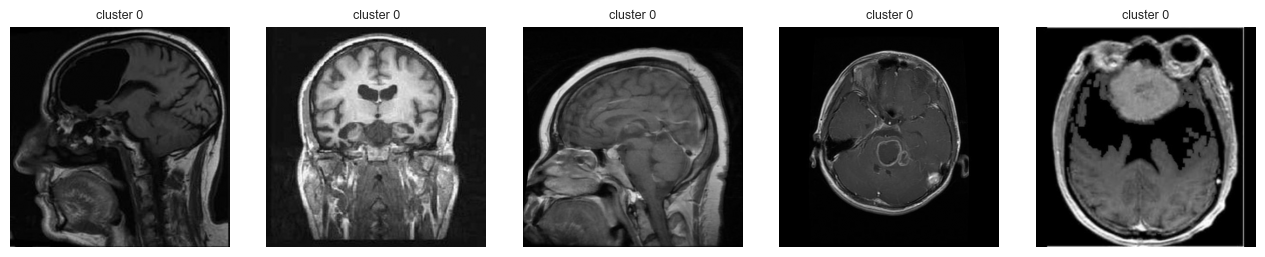

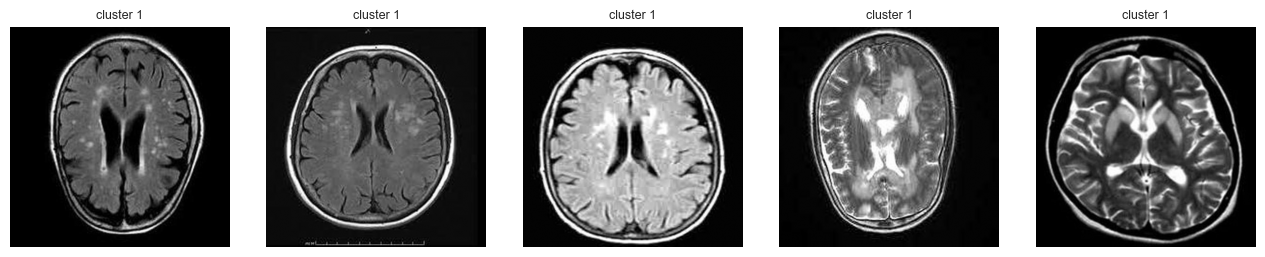

In [12]:
st = pd.read_csv(PROC / 'image_stats.csv').set_index('image_id')
best = results[cc['selected_method']]
chk = pd.DataFrame({'cluster': best.labels, 'mean': st.loc[m.image_id, 'mean'].to_numpy(),
                    'black_ratio': st.loc[m.image_id, 'black_ratio'].to_numpy(),
                    'sharpness': st.loc[m.image_id, 'sharpness'].to_numpy()})
print(chk.groupby('cluster').median().round(2))   # des clusters très différents en luminosité/netteté = biais visuel
from brainscanai.evaluation.plots import plot_sample_grid

def local_path(p):
    """Les chemins du manifeste viennent de Docker (/app/data/raw/...) : on les reconstruit pour cette machine."""
    rel = str(p).replace('\\', '/').split('data/raw/', 1)[-1]
    return str(ROOT / 'data' / 'raw' / rel)

for c in sorted(set(best.labels[best.labels >= 0])):
    idx = np.where(best.labels == c)[0][:5]
    paths = [local_path(p) for p in m.path.iloc[idx]]
    plot_sample_grid(paths, [f'cluster {c}'] * len(idx)); plt.show()

## Labellisation faible
Le mapping cluster → classe est appris sur `strong_train` **uniquement** (voir notebook 04, où le split est créé). Les labels faibles restent dans un jeu séparé (`weak_pool`), jamais mélangé aux labels forts.